In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [2]:
import os, glob

# Point LD_LIBRARY_PATH to Kaggle's pre-installed NVIDIA/CUDA libs before importing TF
nvidia_libs = glob.glob("/usr/local/lib/python*/dist-packages/nvidia/*/lib")
cuda_paths = ["/usr/local/cuda/lib64", "/usr/local/nvidia/lib64"] + nvidia_libs
os.environ["LD_LIBRARY_PATH"] = ":".join(cuda_paths) + ":" + os.environ.get("LD_LIBRARY_PATH", "")
# os.environ["KERAS_BACKEND"] = "torch"
# os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf
print("TF version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())
print("GPUs:", tf.config.list_physical_devices("GPU"))

# Verify an actual GPU tensor op succeeds without cudart_stub fallback
with tf.device("/GPU:0"):
    a = tf.random.normal([1000, 1000])
    b = tf.matmul(a, a)

print("GPU matmul device:", b.device)

I0000 00:00:1795617234.652534      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TF version: 2.21.0
Built with CUDA: True
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
GPU matmul device: /job:localhost/replica:0/task:0/device:GPU:0


In [3]:
from tensorflow.keras.utils import FeatureSpace
from tensorflow.keras.utils import plot_model
# import logging

# # 2. Silence Python level TensorFlow/ABSL warnings
# tf.get_logger().setLevel(logging.ERROR)
# logging.getLogger('tensorflow').setLevel(logging.ERROR)
# logging.getLogger('absl').setLevel(logging.ERROR)

In [4]:
# !pip install -q ipywidgets
# !pip install -q pygraphviz
# !apt-get install -qq -y graphviz graphviz-dev && pip install -qq pydot

In [5]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [6]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import shutil
import itertools
from tqdm.auto import tqdm
from time import time, sleep

from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, PredictionErrorDisplay, RocCurveDisplay
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer, LabelEncoder, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, MissingIndicator, SimpleImputer

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

pd.set_option("display.max_columns", 100)
# sns.set_style("whitegrid")

def seed_everything(seed: int):
    print(f"✓ Seed everything at {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

✓ Seed everything at 42


In [7]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 8,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
# sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [8]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")
    
## =================================================================================

ID = 'id'
TARGET = 'is_fraud'

cat_cols = train.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = train.select_dtypes(exclude=['object', 'bool']).columns.tolist()
base_cols = cat_cols + num_cols

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")
train.head()

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [9]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,699960.0,349979.500000,202061.191548,0.00,174989.75,349979.50,524969.25,699959.00
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90


In [10]:
train_len = len(train)
test_len  = len(test)

float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

int_small = ['txn_count_last_24h', 'cvv_retry_count', 'day_of_week', 'prior_disputes']
int_large = ['card_age_months', 'customer_age', 'time_of_day_hour']

n_unique = train.nunique().sort_values()
n_unique

is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

In [11]:
train[int_large].nunique().sort_values()

time_of_day_hour    24
card_age_months     49
customer_age        64
dtype: int64

In [12]:
train[int_small].nunique().sort_values()

cvv_retry_count        4
prior_disputes         5
day_of_week            7
txn_count_last_24h    12
dtype: int64

In [13]:
def get_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        class_weights = opt
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights
    else:
        classes_ = np.unique(y_true)
        weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
        class_weights = dict(zip(classes_, weights_))
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights

## -- Reduce data memory --
def reduce_memory(df):
    old_size = sys.getsizeof(df) / (1024*1024)
    for c in tqdm(df.columns, desc='Reducing memory...'):
        if df[c].dtype == np.int64:
            ## -- Downcast Integer type ---
            if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
                df[c] = df[c].astype(np.int32)
                # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
                #     df[c] = df[c].astype(np.int16)
                #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
                #         df[c] = df[c].astype(np.int8)
        elif df[c].dtype == np.float64:
            ## -- Downcast Float type -----
            if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
                df[c] = df[c].astype(np.float32)
                # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
                #     df[c] = df[c].astype(np.float16)

    new_size = sys.getsizeof(df) / (1024**2)
    print(f"Size before process: {old_size:.1f}MB\nSize after process : {new_size:.1f}MB\n")

    return df

print('- Helper Functions Ready -')

- Helper Functions Ready -


In [14]:
## -- Groupby features FE -- ⚠️

from typing import List, Optional, Sequence
from sklearn.base import BaseEstimator, TransformerMixin

class GroupbyAggregator(BaseEstimator, TransformerMixin):
    """
    Leak-free groupby feature generator for CV folds and multiple test sets.
    Fits aggregations on training data only and left-joins them onto any DataFrame.
    """

    def __init__(
        self,
        grouper: str,
        agg_cols: List[str],
        aggs: Sequence[str] = ("mean", "std"),
    ):
        self.grouper = grouper
        self.agg_cols = [c for c in agg_cols if c != grouper]
        self.aggs = aggs
        self.stats_: Optional[pd.DataFrame] = None
        self.group_cols_: List[str] = []

    def fit(self, X: pd.DataFrame, y: Optional[pd.Series] = None) -> "GroupbyAggregator":
        """Compute group aggregations strictly on X (e.g., X_train_fold)."""
        target_cols = [col for col in self.agg_cols if col != self.grouper]
        if not target_cols:
            self.stats_ = None
            self.group_cols_ = []
            return self

        prefix = self.grouper.split("_")[0]
        stats = X.groupby(self.grouper, observed=False)[target_cols].agg(list(self.aggs))

        # Flatten MultiIndex columns into clean feature names
        self.group_cols_ = [
            f"{col}_{prefix}_GROUPBY_{agg}".replace(" ", "")
            for col, agg in stats.columns
        ]
        stats.columns = self.group_cols_
        self.stats_ = stats
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        """Map learned group statistics onto X while preserving its original index."""
        if self.stats_ is None or not self.group_cols_:
            return X.copy()

        # Left merge preserves row order; re-assign original index to prevent resets
        merged = X.merge(self.stats_, on=self.grouper, how="left")
        merged.index = X.index
        return merged

    def transform_many(self, *dfs: pd.DataFrame) -> List[pd.DataFrame]:
        """Convenience helper to transform multiple DataFrames in a single call."""
        return [self.transform(df) for df in dfs]


In [15]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_trn, y_trn = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_trn.copy()
            temp_df_train['target'] = y_trn

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_trn.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [16]:
## -- original_TE with factorization --
from typing import List, Optional, Tuple

def original_fcTE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: Optional[List[str]] = None,
    target: Optional[str] = None,
    aggs: Optional[List[str]] = None,
    fill_nan: bool = False,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Applies out-of-fold / external dataset target encoding (TE) from `orig` onto `df`.
    """
    X_df = df.copy()
    orig_df = orig.copy()  # Prevent mutating the caller's original DataFrame

    # 1. Early exit with consistent return signature (DataFrame, list)
    if not features or not aggs or target is None:
        return X_df, []

    if target not in orig_df.columns:
        raise ValueError(f"Target column '{target}' not found in `orig`.")

    # 2. Validate features exist in BOTH DataFrames
    valid_features = [
        col for col in features 
        if col in orig_df.columns and col in X_df.columns
    ]
    
    # Separate 'count' from target-dependent aggregations
    supported_target_aggs = {'mean', 'median', 'nunique', 'std', 'skew', 'max', 'min'}
    clean_aggs = [a.lower() for a in aggs]

    orig_cols = []
    new_features_dict = {}

    for col in tqdm(valid_features, desc="original_augmenting"):
        # Align categorical/object/bool dtypes safely only for needed columns
        if pd.api.types.is_object_dtype(X_df[col]) or \
           isinstance(X_df[col].dtype, pd.CategoricalDtype) or \
           pd.api.types.is_bool_dtype(X_df[col]):
            combined = pd.concat([X_df[col], orig_df[col]], ignore_index=True)
            codes, _ = pd.factorize(combined, sort=True)
            X_df[col] = codes[:len(X_df)]
            orig_df[col] = codes[len(X_df):]

        # Group once per feature instead of once per (feature, agg)
        grouped = orig_df.groupby(col, dropna=False)
        
        # Compute target aggregations in one vectorized pass
        target_aggs_to_run = [a for a in clean_aggs if a in supported_target_aggs]
        if target_aggs_to_run:
            try:
                agg_stats = grouped[target].agg(target_aggs_to_run)
                for agg_key in target_aggs_to_run:
                    new_col = f"oTE_{col}_{agg_key}"
                    # .map() preserves X_df's exact index and row order
                    new_features_dict[new_col] = X_df[col].map(agg_stats[agg_key])
                    orig_cols.append(new_col)
            except Exception as e:
                print(f"Warning: failed target aggs for col={col}: {e}")

        # Handle 'count' separately since it doesn't depend on `target`
        if 'count' in clean_aggs:
            new_col = f"oTE_{col}_count"
            counts = grouped.size()
            new_features_dict[new_col] = X_df[col].map(counts)
            orig_cols.append(new_col)

    # Concatenate all new columns at once to avoid DataFrame fragmentation
    if new_features_dict:
        new_cols_df = pd.DataFrame(new_features_dict, index=X_df.index)
        X_df = pd.concat([X_df, new_cols_df], axis=1)

    # 3. Fill missing values cleanly
    if fill_nan and orig_cols:
        global_mean = orig_df[target].mean()
        global_median = orig_df[target].median()

        fill_values = {}
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                fill_values[c] = global_mean
            elif c.endswith('_median'):
                fill_values[c] = global_median
            else:
                fill_values[c] = 0

        X_df = X_df.fillna(value=fill_values)

    return X_df, orig_cols

print('-- Factorized augment function ready! --')

-- Factorized augment function ready! --


In [17]:
## -- original_TE with objects --
from typing import List, Optional, Tuple

def original_obTE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: Optional[List[str]] = None,
    target: Optional[str] = None,
    aggs: Optional[List[str]] = None,
    fill_nan: bool = False,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Applies external dataset target encoding (TE) from `orig` onto `df`
    while preserving original categorical/string dtypes.
    """
    X_df = df.copy()

    if not features or not aggs or target is None:
        return X_df, []

    if target not in orig.columns:
        raise ValueError(f"Target column '{target}' not found in `orig`.")

    valid_features = [
        col for col in features 
        if col in orig.columns and col in X_df.columns
    ]
    
    supported_target_aggs = {'mean', 'median', 'nunique', 'std', 'skew', 'max', 'min'}
    clean_aggs = [a.lower() for a in aggs]

    orig_cols = []
    new_features_dict = {}

    for col in tqdm(valid_features, desc="original_augmenting"):
        # Group directly on raw strings, objects, or categories (observed=True prevents cartesian blowups)
        grouped = orig.groupby(col, dropna=False, observed=True)
        
        target_aggs_to_run = [a for a in clean_aggs if a in supported_target_aggs]
        if target_aggs_to_run:
            try:
                agg_stats = grouped[target].agg(target_aggs_to_run)
                for agg_key in target_aggs_to_run:
                    new_col = f"oTE_{col}_{agg_key}"
                    # Convert Series to plain dict so CategoricalIndex mismatches don't cause issues
                    mapping_dict = agg_stats[agg_key].to_dict()
                    new_features_dict[new_col] = X_df[col].map(mapping_dict).astype('float32')
                    orig_cols.append(new_col)
            except Exception as e:
                print(f"Warning: failed target aggs for col={col}: {e}")

        if 'count' in clean_aggs:
            new_col = f"oTE_{col}_count"
            counts_dict = grouped.size().to_dict()
            new_features_dict[new_col] = X_df[col].map(counts_dict).astype('float32')
            orig_cols.append(new_col)

    if new_features_dict:
        new_cols_df = pd.DataFrame(new_features_dict, index=X_df.index)
        X_df = pd.concat([X_df, new_cols_df], axis=1)

    if fill_nan and orig_cols:
        global_mean = orig[target].mean()
        global_median = orig[target].median()

        fill_values = {}
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                fill_values[c] = global_mean
            elif c.endswith('_median'):
                fill_values[c] = global_median
            else:
                fill_values[c] = 0

        X_df = X_df.fillna(value=fill_values)

    return X_df, orig_cols

print('-- Object augment function ready! --')

-- Object augment function ready! --


## FEATURE ENGINEERING

In [18]:
# ## -- Numeric to Categorical (TargetEncoding) -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# print("Features before operation:", len(FEATURES))

# combined = pd.concat([train, test], ignore_index=True)
# ## ------------------------------------------------------------
# # -- Duplicate Nums as Cats --
# select_nc = num_cols
# nums_to_cats = []

# for c in tqdm(select_nc, desc="nums_to_cats"):
#     new_cat = f"{c}_CAT_"
#     combined[new_cat], unique = pd.factorize(combined[c], sort=True)
#     # combined[new_cat] = combined[new_cat].astype('int32') #.astype('category')
#     nums_to_cats.append(new_cat)
# ## ------------------------------------------------------------
# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# # orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Features after operation:", train.shape[1])

In [19]:
# ## -- Frequency encoding -- ⚠️
# freq_cols = []
# combined = pd.concat([train, test], ignore_index=True)

# select_freq = cat_cols
# print("\nCreating frequencies (Safe Global Mapping)...")
# for col in select_freq:
#     n = f"{col}_FREQ_"
#     # print(f"⧗ {n}", end="")
#     # Calculate frequencies using ONLY train
#     freq_map = train[col].value_counts(dropna=False, normalize=True).to_dict()
#     # Map the training-derived frequencies across all datasets safely
#     train[n] = train[col].map(freq_map).fillna(0).astype("float32")
#     test[n] = test[col].map(freq_map).fillna(0).astype("float32")
#     orig[n] = orig[col].map(freq_map).fillna(0).astype("float32")
#     freq_cols.append(n)

# print(f"\n *** Total frequency features: {len(freq_cols)}")
# train[freq_cols].nunique()

In [20]:
# ## -- DIGITS extraction -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

# combined = pd.concat([train, test, orig], ignore_index=True)
# digit_cols = []

# for col in num_cols:
#     scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
#     for k in range(-2, 3):
#         dig_col = f"{col}_DIGIT_{k}"
#         combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8') #.astype('category')
#         digit_cols.append(dig_col)

# train = combined.iloc[:train_len]
# test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig = combined.iloc[train_len+test_len:]

# # Check nunique, and find which ones are < 2
# unique_counts = train[digit_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"Total digit features: {len(digit_cols)}\n")

# train[digit_cols].nunique()

In [21]:
# # ## -- Ai suggest: DIGITS extraction -- ⚠️
# combined = pd.concat([train, test, orig], ignore_index=True)
# new_digits = {}

# for col in num_cols:
#     is_na = combined[col].isna()
#     scaled = np.rint(np.abs(combined[col].fillna(0)) * 10**4).astype("int64")
    
#     for k in range(-2, 3):
#         dig_col = f"{col}_DIGIT_{k}"
#         digits = ((scaled // 10**(k + 4)) % 10).astype("int8")
#         digits[is_na] = -1
#         new_digits[dig_col] = digits

# digit_df = pd.DataFrame(new_digits, index=combined.index)

# # Filter constant features based ONLY on train
# train_digits = digit_df.iloc[:train_len]
# unique_counts = train_digits.nunique()
# keep_cols = unique_counts[unique_counts >= 2].index.tolist()

# digit_df = digit_df[keep_cols]

# # Re-attach cleanly without slicing bugs or SettingWithCopyWarning
# train = pd.concat([train.reset_index(drop=True), digit_df.iloc[:train_len].reset_index(drop=True)], axis=1)
# test = pd.concat([test.reset_index(drop=True), digit_df.iloc[train_len:train_len + test_len].reset_index(drop=True)], axis=1)
# orig = pd.concat([orig.reset_index(drop=True), digit_df.iloc[train_len + test_len:].reset_index(drop=True)], axis=1)

# del combined, digit_df, new_digits
# print(f"Total digit features: {len(keep_cols)}\n")
# print(train[keep_cols].nunique())


In [22]:
def digit_keys(df1, cols=float_cols):
    df = df1.copy()
    """How each number is written: six label-free keys per float column."""
    keys = {}
    for c in cols:
        units = np.rint(df[c].to_numpy() * 100).astype(np.int64)        # 1371.37 -> 137137
        integer = units // 100
        s = pd.Series(integer).astype(str)
        keys[f"{c}__int"] = integer                                      # 1371
        keys[f"{c}__int10"] = units // 1000                              # 137
        keys[f"{c}__tenths"] = units // 10                               # 13713
        keys[f"{c}__cents"] = units % 100                                # 37
        keys[f"{c}__lead1"] = (s.str.len() * 10 + s.str[0].astype(int)).to_numpy()     # 4|1
        keys[f"{c}__lead2"] = (s.str.len() * 100 + s.str[:2].astype(int)).to_numpy()   # 4|13

    new_df = pd.DataFrame(keys, index=df.index)
    full_df = pd.concat([df, new_df], axis=1)
    return full_df, [*keys.keys()]

train, digit_cols2 = digit_keys(train)
test, _ = digit_keys(test)
orig, _ = digit_keys(orig)

print(train.shape, test.shape)
train[digit_cols2].nunique()

(699960, 62) (299984, 61)


amount_usd__int                   1144
amount_usd__int10                  235
amount_usd__tenths                4599
amount_usd__cents                  100
amount_usd__lead1                   33
amount_usd__lead2                  217
account_balance_usd__int          4928
account_balance_usd__int10        1116
account_balance_usd__tenths      19083
account_balance_usd__cents         100
account_balance_usd__lead1          28
account_balance_usd__lead2         196
hours_since_last_txn__int           51
hours_since_last_txn__int10          6
hours_since_last_txn__tenths       502
hours_since_last_txn__cents        100
hours_since_last_txn__lead1         15
hours_since_last_txn__lead2         51
distance_from_home_km__int          56
distance_from_home_km__int10         6
distance_from_home_km__tenths      542
distance_from_home_km__cents       100
distance_from_home_km__lead1        15
distance_from_home_km__lead2        56
velocity_score__int                 73
velocity_score__int10    

In [23]:
# ## -- Feature Interactions -- ⚠️

# INTER = []

# combined = pd.concat([train, test], ignore_index=True)
# # ------------------------------------------------------------------------
# # combo_2_1 = list(itertools.combinations(decimal_digits, 2))
# # for c1, c2 in tqdm(combo_2_1, desc="Pairwise Sync Encoding"):
# #     n_col = f"Bi_{c1}_X_{c2}".replace(" ", "")
# #     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str)
# #     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
# #     # combined[n_col] = combined[n_col].astype("category")
# #     INTER.append(n_col)

# # combo_3_1 = list(itertools.combinations(decimal_digits, 3))
# # for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
# #     n_col = f"Tri_{c1}_X_{c2}_X_{c3}".replace(" ", "")
# #     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str) + "_" + combined[c3].astype(str)
# #     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)

# # combo_4_1 = list(itertools.combinations(cat_cols, 4))
# # for c1, c2, c3, c4 in tqdm(combo_4_1, desc='Quadwise Sync Encoding'):
# #     n_col = f"Quad_{c1}_X_{c2}_X_{c3}_X_{c4}".replace(" ", "")
# #     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str) + "_" + combined[c3].astype(str) + "_" + combined[c4].astype(str)
# #     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)

# combo_1_to_many = list(itertools.product(cat_cols, decimal_digits))
# for c1, c2 in tqdm(combo_1_to_many, desc='One-2-Many Sync Encoding'):
#     n_col = f"Bi2_{c1}_X_{c2}".replace(" ", "")
#     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str)
#     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)
# # ------------------------------------------------------------------------

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len]
# # orig  = combined.iloc[train_len+test_len:]

# print(f"Total Interaction Features: {INTER}")

# del combined
# train[INTER].head()

In [24]:
## -- Cyclic encoding --
cyclic_cols = []
cy_cols = ['time_of_day_hour'] # 'txn_count_last_24h'

for col in tqdm(cy_cols):
    for p in [24]:
        n_s = f"{col}_SINE_{p}"
        train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
        test[n_s]  = np.sin(2 * np.pi * test[col] / p).astype('float32')
        orig[n_s]  = np.sin(2 * np.pi * orig[col] / p).astype('float32')
        cyclic_cols.append(n_s)

        # n_c = f"{col}_COSINE_{p}"
        # train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')
        # test[n_c] = np.cos(2 * np.pi * test[col] / p).astype('float32')
        # orig[n_c] = np.cos(2 * np.pi * orig[col] / p).astype('float32')
        # CYCLICS.append(n_c)

# NUMS.extend(CYCLICS)

print(f"Cylcic Features created: {len(cyclic_cols)}")
display(train[cyclic_cols].describe().T)

train[cyclic_cols].head()

  0%|          | 0/1 [00:00<?, ?it/s]

Cylcic Features created: 1


,count,mean,std,min,25%,50%,75%,max
time_of_day_hour_SINE_24,699960.0,-0.025513,0.705248,-1.0,-0.707107,0.0,0.707107,1.0


,time_of_day_hour_SINE_24
0,-0.965926
1,-0.258819
2,-0.707107
3,0.965926
4,0.866025


In [25]:
## -- Interactions function --
# from typing import Iterable, List, Optional, Sequence, Tuple

# def generate_interaction_features(
#     dfs: List[pd.DataFrame],
#     cols: Optional[List[str]] = None,
#     combo_orders: Sequence[int] = (2, 3),
#     product_lists: Optional[List[List[str]]] = None,
#     as_category: bool = False,
# ) -> Tuple[List[pd.DataFrame], List[str]]:
#     """
#     Generate factorized interaction features across up to 3 DataFrames.

#     Args:
#         dfs: List of DataFrames (1 to 3) to encode together and split back in order.
#         cols: Columns used for n-way combinations when product_lists is not provided.
#         combo_orders: Sequence of combination sizes (allowed values: 2, 3, 4).
#         product_lists: List of 2 column lists for Cartesian product interactions.
#                        When provided, combo_orders and cols are ignored.
#         as_category: Convert resulting integer codes to pandas 'category' dtype.

#     Returns:
#         Tuple containing (list of updated DataFrames in original order, list of new feature names).
#     """
#     # --- 1. Input Validation ---
#     if not (1 <= len(dfs) <= 3):
#         raise ValueError(f"`dfs` must contain between 1 and 3 DataFrames, got {len(dfs)}.")

#     if product_lists is not None:
#         if len(product_lists) != 2:
#             raise ValueError(f"`product_lists` must contain at most 2 lists (and at least 2 for a product), got {len(product_lists)}.")
#     else:
#         if not cols:
#             raise ValueError("`cols` must be provided when `product_lists` is None.")
#         valid_orders = {2, 3, 4}
#         if not combo_orders or not set(combo_orders).issubset(valid_orders):
#             raise ValueError(f"`combo_orders` must only contain integers from {valid_orders}, got {combo_orders}.")

#     # --- 2. Combine DataFrames & Track Split Boundaries ---
#     lengths = [len(df) for df in dfs]
#     combined = pd.concat(dfs, ignore_index=True)

#     # --- 3. Build Specs & Pre-cache String Columns ---
#     prefix_map = {2: "Bi", 3: "Tri", 4: "Quad"}
#     interaction_specs: List[Tuple[str, str, Iterable[Tuple[str, ...]]]] = []

#     if product_lists is not None:
#         all_target_cols = set(product_lists[0]) | set(product_lists[1])
#         interaction_specs.append(
#             ("Prod", "Product Sync Encoding", itertools.product(product_lists[0], product_lists[1]))
#         )
#     else:
#         all_target_cols = set(cols)  # type: ignore[arg-type]
#         for order in sorted(set(combo_orders)):
#             prefix = prefix_map[order]
#             interaction_specs.append(
#                 (prefix, f"{order}-Way Sync Encoding", itertools.combinations(cols, order))  # type: ignore[arg-type]
#             )

#     str_cache = {col: combined[col].astype(str) for col in all_target_cols}

#     # --- 4. Generate Factorized Interaction Features ---
#     new_features = {}
#     for prefix, desc, combos in interaction_specs:
#         for col_tuple in tqdm(list(combos), desc=desc):
#             col_name = f"{prefix}_{'_X_'.join(col_tuple)}".replace(" ", "")

#             combined_series = str_cache[col_tuple[0]]
#             for col in col_tuple[1:]:
#                 combined_series = combined_series + "_" + str_cache[col]

#             codes, _ = pd.factorize(combined_series, sort=True)
#             if as_category:
#                 codes = pd.Categorical(codes)
#             new_features[col_name] = codes

#     inter_df = pd.DataFrame(new_features, index=combined.index)
#     combined = pd.concat([combined, inter_df], axis=1)
#     inter_cols = list(new_features.keys())

#     # --- 5. Split Back Into Original Order ---
#     output_dfs: List[pd.DataFrame] = []
#     start = 0
#     for length in lengths:
#         output_dfs.append(combined.iloc[start : start + length].copy())
#         start += length

#     return output_dfs, inter_cols


In [26]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=300_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]

(699960, 63) <class 'pandas.core.frame.DataFrame'>


In [27]:
## -- Handle optional original table aggregations
USE_ORIGINAL = False

import_cols = base_cols

if USE_ORIGINAL:
    aggs_ = ['mean', 'count']  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_obTE(
        orig, train_X, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    x_test, _ = original_obTE(
        orig, test, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int8")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int8")

print(X.shape, type(X))
X.head()

(699960, 61) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,time_of_day_hour_SINE_24
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,61,6,611,16,26,261,1269,126,12693,35,41,412,9,0,97,77,19,109,17,1,177,78,21,217,5,0,55,50,15,105,29,2,292,20,22,229,-0.965926
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,24,2,248,83,22,224,3233,323,32330,0,43,432,1,0,15,54,11,101,13,1,130,6,21,213,33,3,334,40,23,233,29,2,299,90,22,229,-0.258819
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,6,0,63,36,16,106,1046,104,10468,88,41,410,1,0,12,20,11,101,8,0,81,17,18,108,35,3,358,80,23,235,24,2,241,10,22,224,-0.707107
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,37,3,374,44,23,237,2217,221,22176,67,42,422,5,0,51,13,15,105,8,0,86,67,18,108,20,2,207,70,22,220,41,4,419,90,24,241,0.965926
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,653,65,6538,85,36,365,3291,329,32910,6,43,432,0,0,8,80,10,100,11,1,116,69,21,211,34,3,348,80,23,234,48,4,480,0,24,248,0.866025


In [28]:
obj_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()

X[obj_cols] = X[obj_cols].astype(str) #.astype('category')
X_test[obj_cols] = X_test[obj_cols].astype(str) #.astype('category')

# X = reduce_memory(X)
# X_test = reduce_memory(X_test)
# print(f"Data memory reduced!")

FEATURES = [c for c in X.columns if c not in [ID, TARGET]]
print("Total Features:", len(FEATURES))

X.head()

Total Features: 61


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,time_of_day_hour_SINE_24
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,61,6,611,16,26,261,1269,126,12693,35,41,412,9,0,97,77,19,109,17,1,177,78,21,217,5,0,55,50,15,105,29,2,292,20,22,229,-0.965926
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,24,2,248,83,22,224,3233,323,32330,0,43,432,1,0,15,54,11,101,13,1,130,6,21,213,33,3,334,40,23,233,29,2,299,90,22,229,-0.258819
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,6,0,63,36,16,106,1046,104,10468,88,41,410,1,0,12,20,11,101,8,0,81,17,18,108,35,3,358,80,23,235,24,2,241,10,22,224,-0.707107
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,37,3,374,44,23,237,2217,221,22176,67,42,422,5,0,51,13,15,105,8,0,86,67,18,108,20,2,207,70,22,220,41,4,419,90,24,241,0.965926
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,653,65,6538,85,36,365,3291,329,32910,6,43,432,0,0,8,80,10,100,11,1,116,69,21,211,34,3,348,80,23,234,48,4,480,0,24,248,0.866025


In [29]:
# ## -- Reduce data memory --

# def reduce_memory(df, factorize_first=False):
#     # Use copy() if you want to avoid modifying the original dataframe in place
#     # df = df.copy()

#     old_size = df.memory_usage(deep=True).sum() / (1024 * 1024)

#     for c in tqdm(df.columns, desc='Reducing memory...'):
#         col_type = df[c].dtype
#         # Check if type is bool (True or False)
#         if col_type == bool:
#             if factorize_first:
#                 df[c], _ = df[c].factorize(sort=True)
#                 df[c] = df[c].astype('category')
#             else:
#                 df[c] = df[c].astype(str).astype('category')
#         ## - Check if type is integer
#         elif np.issubdtype(col_type, np.integer):
#             df[c] = pd.to_numeric(df[c], downcast='integer')
#         ## - Optional: Convert object types with low cardinality to category
#         elif col_type == object or col_type.name == 'category':
#             if df[c].nunique() < len(df[c]) * 0.5:  # If less than 50% unique values
#                 if factorize_first:
#                     df[c], _ = df[c].factorize(sort=True)
#                     df[c] = df[c].astype('category')
#                 else:
#                     df[c] = df[c].astype('category')
#         # Check if type is float
#         # elif np.issubdtype(col_type, np.floating):
#         #     df[c] = pd.to_numeric(df[c], downcast='float')

#     new_size = df.memory_usage(deep=True).sum() / (1024 * 1024)
#     print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f} MB\n")

#     return df

# X = reduce_memory(X, factorize_first=False)
# X_test = reduce_memory(X_test, factorize_first=False)
# # orig = reduce_memory(orig)

# print(f"Data memory reduced!")
# gc.collect()

# X.head()

In [30]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 61 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   amount_usd                     699960 non-null  float64
 1   hours_since_last_txn           699960 non-null  float64
 2   txn_count_last_24h             699960 non-null  int64  
 3   distance_from_home_km          699960 non-null  float64
 4   card_age_months                699960 non-null  int64  
 5   customer_age                   699960 non-null  int64  
 6   account_balance_usd            699960 non-null  float64
 7   cvv_retry_count                699960 non-null  int64  
 8   velocity_score                 699960 non-null  float64
 9   time_of_day_hour               699960 non-null  int64  
 10  day_of_week                    699960 non-null  int64  
 11  merchant_risk_score            699960 non-null  float64
 12  prior_disputes                

# ML TRAINING

In [31]:
# def build_keras_mlp(
#     feature_space: tf.keras.utils.FeatureSpace = None,
#     layer_units: list = [128, 64, 32],
#     learning_rate: float = 0.01,
#     drop_rate: float = 0.1,
#     activation: str = "relu",
#     bias: bool = True,
#     l2_reg = tf.keras.regularizers.L2(0.0)
# ):
#     # 1. Retrieve structural components from the globally adapted FeatureSpace
#     dict_inputs = feature_space.get_inputs()
#     encoded_features = feature_space.get_encoded_features()

#     print(f"Input shape: {len(dict_inputs)}", end=" | ")
#     print(f"FeatureSpace shape: {encoded_features.shape[1]} +++ MLP model +++")
#     print('-'*60)

#     # 2. Build the Core Deep Neural Network using the Functional API safely
#     # This ensures layers are completely reusable across train/inference topologies
#     x = encoded_features

#     # Clean, dynamic looping over layer configuration list
#     for units in layer_units:
#         x = tf.keras.layers.Dense(
#             units,
#             activation=activation,
#             use_bias=bias,
#             kernel_regularizer=l2_reg)(x)
#         x = tf.keras.layers.BatchNormalization()(x)
#         x = tf.keras.layers.Dropout(drop_rate)(x)

#     # Final Binary Classification Output Node
#     final_output = tf.keras.layers.Dense(1, activation="sigmoid")(x)

#     train_model = tf.keras.Model(inputs=encoded_features, outputs=final_output)
#     infer_model = tf.keras.Model(inputs=dict_inputs, outputs=final_output)

#     train_model.compile(
#         optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, weight_decay=0.0),
#         loss="binary_crossentropy",
#         metrics=[tf.keras.metrics.AUC(name="auc")]
#     )

#     return train_model, infer_model

# print("⚙️ Keras mlp model ready ⚙️")

In [32]:
# def build_keras_seq(
#     feature_space: tf.keras.utils.FeatureSpace = None,
#     layer_units: list = [128, 64, 32],
#     learning_rate: float = 0.01,
#     drop_rate: float = 0.1,
#     activation: str = "relu",
#     bias: bool = True,
#     l2_reg = tf.keras.regularizers.L2(0.0),
# ):

#     # 1. Setup Inputs
#     dict_inputs = feature_space.get_inputs()
#     encoded_features = feature_space.get_encoded_features()

#     print(f"Input shape: {len(dict_inputs)}", end=" | ")
#     print(f"FeatureSpace shape: {encoded_features.shape[1]} +++ Sequential model +++")
#     print('-'*60)

#     # 2. Create the Sequential model
#     outputs = tf.keras.Sequential([
#         # keras.Input(shape=shape),
#         # Optional: Add BN here if your data isn't pre-scaled
#         # keras.layers.BatchNormalization(),

#         ## -- 1st Layer --
#         tf.keras.layers.Dense(layer_units[0], activation, use_bias=bias,
#                               kernel_regularizer=l2_reg),
#         tf.keras.layers.BatchNormalization(),
#         # tf.keras.layers.Activation('relu'),
#         tf.keras.layers.Dropout(drop_rate),

#         ## -- 2nd Layer --
#         tf.keras.layers.Dense(layer_units[1], activation, use_bias=bias,
#                               kernel_regularizer=l2_reg),
#         tf.keras.layers.BatchNormalization(),
#         # tf.keras.layers.Activation('relu'),
#         tf.keras.layers.Dropout(drop_rate),

#         ## -- 3rd Layer --
#         tf.keras.layers.Dense(layer_units[2], activation, use_bias=bias,
#                               kernel_regularizer=l2_reg),
#         tf.keras.layers.BatchNormalization(),
#         # keras.layers.Activation('relu'),
#         tf.keras.layers.Dropout(drop_rate),

#         ## -- Output --
#         tf.keras.layers.Dense(1, activation="sigmoid")
#     ])(encoded_features)

#     # Connect everything
#     train_model = tf.keras.Model(inputs=encoded_features, outputs=outputs)
#     train_model.compile(
#         # optimizer=keras.optimizers.Adam(learning_rate, weight_decay=None), # 0.02
#         # optimizer=tf.keras.optimizers.RMSprop(learning_rate),
#         optimizer=tf.keras.optimizers.Adam(learning_rate, weight_decay=0.0),
#         loss="binary_crossentropy",
#         metrics=[tf.keras.metrics.AUC(name="auc")]
#         )

#     infer_model = tf.keras.Model(inputs=dict_inputs, outputs=outputs)

#     return train_model, infer_model

# print("⚙️ Keras sequential model ready ⚙️")

In [33]:
# def _feature_space_transform(X, y, batch_size=4096, feat_crosses=None):
#     """Initializes and adapts Keras FeatureSpace globally once."""

#     obj_cols = X.select_dtypes(include=["object", "bool"]).columns.tolist()
#     te_cols = [c for c in X.columns if c.startswith(("TE_", "oTE_"))]

#     feature_specs = {}
#     for col in X.columns:
#         if col in obj_cols:
#             feature_specs[col] = FeatureSpace.string_categorical()
#         elif col in float_cols:
#             feature_specs[col] = FeatureSpace.float_discretized(32)
#         elif col in int_large:
#             feature_specs[col] = FeatureSpace.float_discretized(6)
#         elif col in int_small:
#             feature_specs[col] = FeatureSpace.integer_categorical()
#         elif col in cyclic_cols:
#             feature_specs[col] = FeatureSpace.float_normalized()
#         elif col in te_cols:
#             feature_specs[col] = FeatureSpace.float_normalized()
#         # elif col in digit_cols2:
#         #     feature_specs[col] = FeatureSpace.float_discretized(32)

#     if feat_crosses is not None:
#         get_crosses = [FeatureSpace.cross(combo, crossing_dim=8) for combo in feat_crosses]
#     else:
#         get_crosses = None

#     _fs = FeatureSpace(
#         features=feature_specs,
#         crosses=get_crosses,
#         output_mode="concat",
#         name="fs_processed",
#     )
#     ds = tf.data.Dataset.from_tensor_slices((dict(X), y)).batch(batch_size)
#     no_labels = ds.map(lambda x, _: x)
#     print(f"📥 FeatureSpace.adapt(): {len(feature_specs)} features... ", end='')

#     _fs.adapt(no_labels)
#     print(f"✅ Complete!")

#     return _fs

# print("⚙️ Feature_Space function ready ⚙️")

In [34]:
def build_keras_mlp(
    input_dim: int,
    layer_units: list = [128, 64, 32],
    learning_rate: float = 0.01,
    drop_rate: float = 0.1,
    activation: str = "relu",
    bias: bool = True,
    l2_reg=tf.keras.regularizers.L2(0.0),
):
    inputs = tf.keras.Input(shape=(input_dim,), name="encoded_features")
    print(f"Input shape: {input_dim} +++ MLP model +++")
    print("-" * 60)

    x = inputs
    for units in layer_units:
        x = tf.keras.layers.Dense(
            units, activation=activation, use_bias=bias, kernel_regularizer=l2_reg
        )(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Dropout(drop_rate)(x)

    final_output = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inputs=inputs, outputs=final_output)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, weight_decay=0.0),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc")],
    )
    return model

In [35]:
def build_keras_seq(
    input_dim: int,
    layer_units: list = [128, 64, 32],
    learning_rate: float = 0.01,
    drop_rate: float = 0.1,
    activation: str = "relu",
    bias: bool = True,
    l2_reg=tf.keras.regularizers.L2(0.0),
):
    print(f"Input shape: {input_dim} +++ Sequential model +++")
    print("-" * 60)

    layers = [tf.keras.Input(shape=(input_dim,), name="encoded_features")]

    for units in layer_units:
        layers.extend([
            tf.keras.layers.Dense(
                units, activation=activation, use_bias=bias, kernel_regularizer=l2_reg
            ),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.Dropout(drop_rate),
        ])

    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))

    model = tf.keras.Sequential(layers)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, weight_decay=0.0),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc")],
    )
    return model

In [36]:
def _feature_space_transform(X, y, batch_size=64, adapt_samples=100_000, feat_crosses=None):
    """Initializes and adapts Keras FeatureSpace rapidly using a stratified subsample."""
    obj_cols = X.select_dtypes(include=["object", "bool"]).columns.tolist()
    te_cols = [c for c in X.columns if c.startswith(("TE_", "oTE_"))]
    feature_specs = {}

    for col in X.columns:
        if col in obj_cols:
            feature_specs[col] = FeatureSpace.string_categorical()
        elif col in float_cols:
            feature_specs[col] = FeatureSpace.float_discretized(32)
        elif col in int_large:
            feature_specs[col] = FeatureSpace.int_discretized(6)
        elif col in int_small:
            feature_specs[col] = FeatureSpace.integer_categorical()
        elif col in cyclic_cols:
            feature_specs[col] = FeatureSpace.float_normalized()
        elif col in te_cols:
            feature_specs[col] = FeatureSpace.float_normalized()

    get_crosses = (
        [FeatureSpace.cross(combo, crossing_dim=8) for combo in feat_crosses]
        if feat_crosses is not None
        else None
    )

    _fs = FeatureSpace(
        features=feature_specs,
        crosses=get_crosses,
        output_mode="concat",
        name="fs_processed",
    )

    # Subsample for fast .adapt() (vocab & quantile edges converge well before 100k rows)
    if adapt_samples is not None and len(X) > adapt_samples:
        X_adapt, _ = train_test_split(X, train_size=adapt_samples, stratify=y, random_state=42)
    else:
        X_adapt = X

    # Convert columns to contiguous numpy arrays before building tf.data
    adapt_dict = {col: X_adapt[col].to_numpy() for col in feature_specs.keys()}
    ds = tf.data.Dataset.from_tensor_slices(adapt_dict).batch(batch_size)

    print(f"📥 FeatureSpace.adapt(): {len(feature_specs)} features on {len(X_adapt):,} rows... ", end="")
    t0 = time()
    _fs.adapt(ds)
    print(f"✅ Finished in {(time()-t0)/60.0:.2f} mins")
    return _fs

In [37]:
CHECKPOINT = "checkpoints/"
shutil.rmtree(CHECKPOINT, ignore_errors=True)
os.makedirs(CHECKPOINT, exist_ok=True)

class CFG:
    TE    = True if 'digit_cols2' in globals() else False
    BIAS  = True   # d=True
    MODEL = 'MLP'  # 'MLP', 'SEQ'
    ACT   = 'relu' # 'relu', 'selu', 'gelu'
    LR    = 0.01
    EPOCH = 15
    STOP  = 4
    DROP  = 0.1
    UNITS = [512, 256, 128]
    BATCH = 1024 if torch.cuda.is_available() else 128

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        patience=CFG.STOP,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=f"{CHECKPOINT}best_model.model.keras",
        monitor="val_auc",
        save_best_only=True,
    ),
]

dir(CFG)[:10]

['ACT', 'BATCH', 'BIAS', 'DROP', 'EPOCH', 'LR', 'MODEL', 'STOP', 'TE', 'UNITS']

In [38]:
AUTOTUNE = tf.data.AUTOTUNE 

def make_async_dataset(X_df, y_series=None, feature_space=None, batch_size=1024, shuffle=False, seed=42):
    if y_series is not None:
        ds = tf.data.Dataset.from_tensor_slices((dict(X_df), y_series))
        if shuffle:
            ds = ds.shuffle(buffer_size=len(X_df), seed=seed)
        ds = ds.batch(batch_size)
        # Asynchronous preprocessing on CPU while GPU trains
        ds = ds.map(lambda x, y: (feature_space(x), y), num_parallel_calls=AUTOTUNE)
    else:
        ds = tf.data.Dataset.from_tensor_slices(dict(X_df))
        ds = ds.batch(batch_size)
        ds = ds.map(lambda x: feature_space(x), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


# -- TRAINER --
FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)
model_name = f"KerasFS_{CFG.ACT[:2]}({X.shape[1]}_{CFG.UNITS[0]}_{str(CFG.DROP).split('.')[1]})"
print(f"🚀 Training {model_name} with {FOLDS} Folds | device: {get_system_info()}\n")

# Single-GPU / CPU setup (no MirroredStrategy needed for 1x Tesla T4)
gpus = tf.config.list_physical_devices("GPU")
print(f"⚙️ TF Physical GPUs detected: {len(gpus)}")
BATCH_SIZE = CFG.BATCH
print(f"⚙️ Batch size: {BATCH_SIZE}\n")

oof_preds = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_times = []
fold_scores = []
fold_histories = []
best_iterations = []
fold_results = []

t0 = time()

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    tf.keras.backend.clear_session()
    X_trn, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()

    print("=" * 15)
    print(f"### Fold {fold}/{FOLDS}")
    print("=" * 15)
    f0 = time()

    # 1. Target encoding (fold-safe)
    if CFG.TE:
        te_cols = digit_cols2
        smooth = "auto"
        print(f"⚡️ TargetEncoding ({len(te_cols)}) • smooth={smooth}")
        TE = skTE(target_type="binary", cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE_{smooth}_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        X_trn = X_trn.drop(columns=te_cols)
        X_val = X_val.drop(columns=te_cols)
        X_tst = X_tst.drop(columns=te_cols)

    # 2. Adapt FeatureSpace on training fold only
    _fs = _feature_space_transform(X_trn, y_trn)
    encoded_dim = _fs.get_encoded_features().shape[1]

    # 3. Build decoupled numeric model (MLP or Sequential)
    model_fn = build_keras_mlp if CFG.MODEL == "MLP" else build_keras_seq
    train_model = model_fn(
        input_dim=encoded_dim,
        layer_units=CFG.UNITS,
        learning_rate=CFG.LR,
        drop_rate=CFG.DROP,
        activation=CFG.ACT,
        bias=CFG.BIAS,
    )

    # 4. Build asynchronous prefetched datasets
    train_ds = make_async_dataset(X_trn, y_trn, _fs, batch_size=BATCH_SIZE, shuffle=True, seed=42)
    valid_ds = make_async_dataset(X_val, y_val, _fs, batch_size=BATCH_SIZE, shuffle=False)

    fold_ckpt = f"{CHECKPOINT}best_model_fold{fold}.keras"
    fold_callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_auc", mode="max", patience=CFG.STOP, restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=fold_ckpt, monitor="val_auc", mode="max", save_best_only=True
        ),
    ]

    print("    🟢 Training Model Graph (Async Preprocessing)...")
    history = train_model.fit(
        train_ds,
        validation_data=valid_ds,
        epochs=CFG.EPOCH,
        callbacks=fold_callbacks,
        verbose=1,
    )

    # 5. Out-of-fold & Test inference
    val_infer_ds = make_async_dataset(X_val, feature_space=_fs, batch_size=BATCH_SIZE)
    tst_infer_ds = make_async_dataset(X_tst, feature_space=_fs, batch_size=BATCH_SIZE)

    val_preds = train_model.predict(val_infer_ds, verbose=0).ravel()
    oof_preds[val_idx] = val_preds
    test_preds += train_model.predict(tst_infer_ds, verbose=0).ravel() / FOLDS

    # 6. Metrics & Logging
    fold_auc = roc_auc_score(y_val, val_preds)
    best_ep = int(np.argmax(history.history["val_auc"]) + 1)
    elapsed_min = (time() - f0) / 60.0

    fold_scores.append(fold_auc)
    fold_histories.append(history.history)
    best_iterations.append(best_ep)
    fold_times.append(elapsed_min)
    fold_results.append({"auc": round(fold_auc, 5), "epoch": best_ep, "time(min)": round(elapsed_min, 2)})

    print("-" * 45)
    print(f"# Fold {fold} AUC: {fold_auc:.5f} [ epoch={best_ep}, time={elapsed_min:.2f}mins ]\n")

    del X_trn, X_val, X_tst, train_ds, valid_ds, val_infer_ds, tst_infer_ds, _fs, train_model
    gc.collect()

tt = (time() - t0) / 60.0
oof_auc = roc_auc_score(y, oof_preds)
avg_auc = np.mean(fold_scores)
std_auc = np.std(fold_scores)

print("=" * 50)
print(f"5-FOLD CV: {model_name} | {X.shape}")
print("=" * 50)
print(f"OOF score: {oof_auc:.5f}")
print(f"AVG score: {avg_auc:.5f} ± {std_auc:.5f}")
print(f"Total time: {tt:.2f} mins")

🚀 Training KerasFS_re(61_512_1) with 5 Folds | device: GPU: Tesla T4

⚙️ TF Physical GPUs detected: 2
⚙️ Batch size: 1024

### Fold 1/5
⚡️ TargetEncoding (36) • smooth=auto
📥 FeatureSpace.adapt(): 61 features on 100,000 rows... ✅ Finished in 4.55 mins
Input shape: 337 +++ MLP model +++
------------------------------------------------------------
    🟢 Training Model Graph (Async Preprocessing)...
Epoch 1/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 54s 51ms/step - auc: 0.8911 - loss: 0.0701 - val_auc: 0.9278 - val_loss: 0.0477
Epoch 2/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 36s 36ms/step - auc: 0.9348 - loss: 0.0466 - val_auc: 0.9287 - val_loss: 0.0469
Epoch 3/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 35s 35ms/step - auc: 0.9381 - loss: 0.0459 - val_auc: 0.9331 - val_loss: 0.0472
Epoch 4/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 36s 35ms/step - auc: 0.9406 - loss: 0.0449 - val_auc: 0.9197 - val_loss: 0.0483
Epoch 5/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 35s 35ms/step - auc: 0.9459 - loss: 0.0442 - val_auc: 0.9279 - val_loss: 0.0479


In [ ]:
# tf.keras.backend.clear_session()

In [ ]:
# # -- TRAINER --

# FOLDS = 5
# skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

# model_name = f"KerasFS_{CFG.ACT[:2]}({X.shape[1]}_{CFG.UNITS[0]}_{str(CFG.DROP).split('.')[1]})"
# print(f"🚀 Training {model_name} with {FOLDS } Folds | device: {get_system_info()}\n")

# # -----------------------------------------------------------
# try:
#     tpu = tf.distribute.cluster_resolver.TPUClusterResolver()
#     tf.config.experimental_connect_to_cluster(tpu)
#     tf.tpu.experimental.initialize_tpu_system(tpu)
#     strategy = tf.distribute.TPUStrategy(tpu)
# except ValueError:
#     strategy = tf.distribute.MirroredStrategy()

# BATCH_SIZE = CFG.BATCH * strategy.num_replicas_in_sync
# print(f"⚙️ Number of devices: {strategy.num_replicas_in_sync}")
# print(f"⚙️ Total batch sizee: {BATCH_SIZE}\n")
# # -------------------------------------------------------------

# oof_preds  = np.zeros(len(X))
# test_preds = np.zeros(len(X_test))

# fold_times = []
# fold_scores = []
# fold_histories = []
# best_iterations = []

# _cats_ = [c for c in cat_cols if c.endswith(("_cat_", "_bin_"))] #

# t0 = time()
# for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
#     X_trn, X_val = X.iloc[tr_idx], X.iloc[val_idx]
#     y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
#     X_tst = X_test.copy()

#     print("="*15)
#     print(f"### Fold {fold}/{FOLDS}")
#     print("="*15)

#     f0 = time()
#     # Target encoding
#     if CFG.TE:
#         te_cols = digit_cols2
#         smooth  = 'auto'
#         print(f"⚡️ TargetEncoding ({len(te_cols)}) • smooth={smooth}")
#         TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
#         tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
#         va_enc = TE.transform(X_val[te_cols])
#         ts_enc = TE.transform(X_tst[te_cols])

#         te_names = [f"TE_{col}" for col in te_cols]
#         X_trn[te_names] = tr_enc
#         X_val[te_names] = va_enc
#         X_tst[te_names] = ts_enc

#         combos_to_drop = te_cols
#         X_trn = X_trn.drop(columns=combos_to_drop )
#         X_val = X_val.drop(columns=combos_to_drop )
#         X_tst = X_tst.drop(columns=combos_to_drop )
#     # --------------------------------------------------------------------
#     # ---- Imputation ----
#     impute_nums = X_trn.columns[X_trn[X_trn.columns].isna().any()].tolist()
#     # impute_nums = [c for c in X_trn.columns if c not in CATS]

#     if len(impute_nums) > 0:
#         print('⚡️ Imputing NaN values')
#         imputer = SimpleImputer() #.set_output(transform="pandas")
#         X_trn[impute_nums] = imputer.fit_transform(X_trn[impute_nums], y_trn)
#         X_val[impute_nums] = imputer.transform(X_val[impute_nums])
#         X_tst[impute_nums] = imputer.transform(X_tst[impute_nums])
#     # --------------------------------------------------------------------
#     # ---- FeatureSpace Adaptation ----  
#     FS_module = _feature_space_transform(
#         X=X_trn,
#         y=y_trn,
#         batch_size=BATCH_SIZE,
#         # feat_crosses=None, # list of tuple-pairs ->[(). (), ()]
#     )

#     # PERFORMANCE FIX: Formulate explicit dictionary naming structures mapping directly into placeholders
#     X_trn_ds = tf.data.Dataset.from_tensor_slices((dict(X_trn), y_trn)).batch(BATCH_SIZE)
#     prep_trn_ds = (X_trn_ds.map(
#         lambda x, y: (FS_module(x), y), 
#         num_parallel_calls=tf.data.AUTOTUNE
#     ).cache().shuffle(buffer_size=len(X_trn)).prefetch(tf.data.AUTOTUNE))

#     X_val_ds = tf.data.Dataset.from_tensor_slices((dict(X_val), y_val)).batch(BATCH_SIZE)
#     prep_val_ds = (X_val_ds.map(
#         lambda x, y: (FS_module(x), y), 
#         num_parallel_calls=tf.data.AUTOTUNE
#     ).cache().prefetch(tf.data.AUTOTUNE))

#     # Distribute execution matrices smoothly over available cores
#     dist_train_ds = strategy.experimental_distribute_dataset(prep_trn_ds)
#     dist_valid_ds = strategy.experimental_distribute_dataset(prep_val_ds)

#     # Wrap model building and compiling inside the active strategy scope block
#     with strategy.scope():
#         model = build_keras_mlp if CFG.MODEL == 'MLP' else build_keras_seq
#         train_model, infer_model = model(
#             feature_space=FS_module,
#             drop_rate=CFG.DROP,
#             layer_units=CFG.UNITS,
#             learning_rate=CFG.LR,
#             activation=CFG.ACT,
#             bias=CFG.BIAS,
#         )

#     print(f"    🟢 Training Model Graph...")
#     history = train_model.fit(
#         dist_train_ds,
#         validation_data=dist_valid_ds,
#         epochs=CFG.EPOCH,
#         callbacks=callbacks,
#         verbose=1,
#     )
#     fold_histories.append(history.history)

#     # CACHING INFERENCE CHANNELS: Cache transformed evaluation datasets to save CPU cycles
#     X_val_infer_ds = tf.data.Dataset.from_tensor_slices(dict(X_val))\
#                                     .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
#     X_tst_infer_ds = tf.data.Dataset.from_tensor_slices(dict(X_tst))\
#                                     .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

#     # HIGH EFFICIENCY PREDICTION: Route raw data dictionaries directly into the inference graph
#     # print(f"    🔵 Evaluating Out-of-Fold Predictions...")
#     val_preds = infer_model.predict(X_val_infer_ds).ravel()
#     oof_preds[val_idx] = val_preds

#     # print(f"    🟡 Calculating Test Inferences...")
#     fold_test_preds = infer_model.predict(X_tst_infer_ds).ravel()
#     test_preds += fold_test_preds

#     fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
#     fold_scores.append(fold_score)

#     best_iter = len([*history.history.values()])
#     best_iterations.append(best_iter)

#     f1 = time()
#     ff = np.round((f1-f0)/60, 2)
#     fold_times.append(ff)

#     if torch.cuda.is_available():
#         torch.cuda.empty_cache()

#     print("-"*45)
#     print(f"{Fore.YELLOW}{Style.BRIGHT}# Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
#     print(f"[ epoch={best_iter}, time={ff}mins ]\n")

# test_preds /= FOLDS

# print(f"\n{'='*50}")
# print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
# print(f"{'='*50}")

# for i, (score, epoch, dura) in enumerate(zip(fold_scores, best_iterations, fold_times), 1):
#     print(f" • Fold {i} AUC: {score} @ epoch={epoch} in {dura}mins")

# ## -- Final out-of-fold score --
# oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
# avg_auc = np.round(np.mean(fold_scores), 5)
# std_auc = np.round(np.std(fold_scores), 5)

# ## -- CV results --
# fold_results = {}
# fold_results[f'auc'] = fold_scores
# fold_results[f'epoch'] = best_iterations
# fold_results[f'time(min)'] = fold_times

# print("-"*50)
# print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
# print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
# print("-"*50)

# t1 = time()
# tt = (t1-t0)/60
# print(f"{tt:.2f} mins\n")

# del FS_module, dist_train_ds, dist_valid_ds, X_val_infer_ds, X_tst_infer_ds

In [ ]:
# ==================================================
# 5-FOLD CV: KerasFS_re(61_512_1) | (699960, 61)
# ==================================================
# OOF score: 0.94364
# AVG score: 0.94378 ± 0.00263
# Total time: 98.95 mins

# ======================================== BIAS=True
# 5-FOLD CV: KerasFS_re(24_512_1) | (559968, 24)
# ==================================================
#  • Fold 1 AUC: 0.93306 @ epoch=4
#  • Fold 2 AUC: 0.94038 @ epoch=4
#  • Fold 3 AUC: 0.94202 @ epoch=4
#  • Fold 4 AUC: 0.93726 @ epoch=4
#  • Fold 5 AUC: 0.93198 @ epoch=4
# --------------------------------------------------
# OOF score: 0.93549
# AVG score: 0.93694 ± 0.00393
# --------------------------------------------------
# 35.35 mins

In [ ]:
# dir(train_model)
# for v in history.history.values():
#     print(v)

In [37]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-'*30)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-'*30)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

-------------------------
KerasFS_re(61_512_1)_9437794563955062
-------------------------
98.9 mins



,auc,epoch,time(min)
fold 1,0.94400,2,19.29
fold 2,0.94366,4,20.61
fold 3,0.94807,2,19.41
fold 4,0.94337,3,19.72
fold 5,0.93979,3,19.81


In [38]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000107
1,699961,0.000102
2,699962,0.123622
3,699963,0.001525
4,699964,0.000416


In [39]:
# !rm -r /kaggle/working

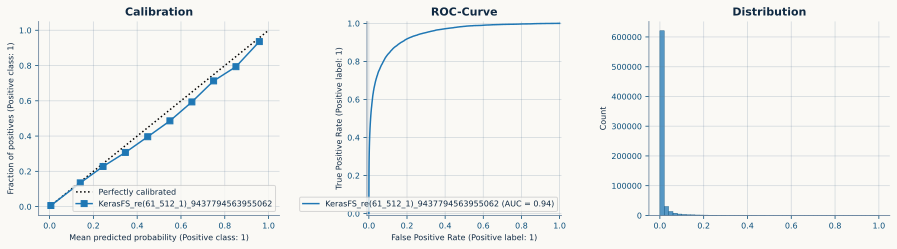

In [40]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 3.5))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout(w_pad=0.2)
plt.show()

In [ ]:
# histories = {}
# fold_scores = {}

# for k, v in all_predictions.items():
#     for x, y in v.items():
#         if x == "history":
#             histories[k] = y
#         elif x == "fold_score":
#             fold_scores[k] = y

# fold_scores

In [ ]:
# for i, (data, score) in tqdm(enumerate(zip(histories.values(), fold_scores.values()))):
#     print("Hist", data[i]['auc'])
#     print(score[i])
#     break

In [ ]:
# ## -- Plot results --
# histories = {}

# for i, (k, v) in enumerate(all_predictions.items()):
#     for j, (x, y) in enumerate(v.items()):
#         if x == "history":
#             histories[k] = y
#             # print(y)
#             loss_results = pd.DataFrame({'train_loss': y[i]['loss'], 'val_loss': y[i]['val_loss']})
#             auc_results  = pd.DataFrame({'train_auc': y[i]['auc'], 'val_auc': y[i]['val_auc']})

#             plt.figure(figsize=(16, 5))
#             marker = 'o'

#             ## -- Plot LOSS --
#             plt.subplot(121)
#             sns.lineplot(loss_results, x=loss_results.index, y=loss_results.train_loss, label='train_loss', marker=marker)
#             sns.lineplot(loss_results, x=loss_results.index, y=loss_results.val_loss, label='val_loss', marker=marker)
#             plt.title(f"- LOSS -", fontweight='semibold')
#             plt.xlabel('Epochs')
#             plt.ylabel('Loss')
        
#             ## -- Plot AUC --
#             plt.subplot(122)
#             sns.lineplot(auc_results, x=auc_results.index, y=auc_results.train_auc, label='train_auc', marker=marker)
#             sns.lineplot(auc_results, x=auc_results.index, y=auc_results.val_auc, label='val_auc', marker=marker)
#             plt.title(f"- AUC -", fontweight='semibold')
#             plt.xlabel('Epochs')
#             plt.ylabel('AUC')
#             min_value = min(min(auc_results.train_auc)-1e-3, min(auc_results.val_auc-1e-3))
#             max_value = max(max(auc_results.train_auc+1e-3), max(auc_results.val_auc+1e-3))
#             plt.ylim((min_value, max_value))

#             stat_ = f"fold_auc: {fold_scores[k][i]:.6f}"
#             plt.scatter(x=0, y=0, label=stat_, color='g')
        
#             plt.suptitle(f"{k}: FOLD {i+1}", fontsize=15, fontweight='semibold')
#             plt.legend(loc='lower right')
#             plt.tight_layout()
#             plt.show()
        
#             print()
        
#             # break

In [ ]:
# ## -- Plotting results --

# for i, (k, v) in enumerate(histories.items()):
#     print(k)
#     for j, (fold, score) in enumerate(zip(v, fold_score)):
#         loss_results = pd.DataFrame({'train_loss': fold['loss'], 'val_loss': fold['val_loss']})
#         auc_results = pd.DataFrame({'train_auc': fold['auc'], 'val_auc': fold['val_auc']})
#         plt.figure(figsize=(16, 5))
#         marker = 'o'
    
#         ## -- PLOT LOSS --
#         plt.subplot(121)
#         sns.lineplot(loss_results, x=loss_results.index, y=loss_results.train_loss, label='train_loss', marker=marker)
#         sns.lineplot(loss_results, x=loss_results.index, y=loss_results.val_loss, label='val_loss', marker=marker)
#         plt.title(f"{k} LOSS", fontweight='semibold')
#         plt.xlabel('Epochs')
#         plt.ylabel('Loss')
    
#         ## -- PLOT AUC --
#         plt.subplot(122)
#         sns.lineplot(auc_results, x=auc_results.index, y=auc_results.train_auc, label='train_auc', marker=marker)
#         sns.lineplot(auc_results, x=auc_results.index, y=auc_results.val_auc, label='val_auc', marker=marker)
#         plt.title(f"{k} AUC", fontweight='semibold')
#         plt.xlabel('Epochs')
#         plt.ylabel('AUC')
#         min_value = min(min(auc_results.train_auc)-1e-3, min(auc_results.val_auc-1e-3))
#         max_value = max(max(auc_results.train_auc+1e-3), max(auc_results.val_auc+1e-3))
#         plt.ylim((min_value, max_value))
    
#         stat_ = f"fold_auc: {score[j]:.6f}"
#         plt.scatter(x=0, y=0, label=stat_, color='y')
    
#         plt.suptitle(f"FOLD {j+1}", fontsize=15, fontweight='semibold')
#         plt.legend(loc='best')
#         plt.tight_layout()
#         plt.show()
#         print()

In [ ]:
# if len(model_results.columns) > 1:
#     # display(model_results.corr("spearman"))
#     fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
#     sns.heatmap(model_results.corr("spearman"), annot=True, fmt=".4g", cbar=False, ax=ax1)
#     ax1.set_title('Heatmap Correlation (Spearman)', fontsize=14, fontweight='bold')
    
#     sns.ecdfplot(data=model_results, linewidth=2, ax=ax2)
#     ax2.set_title('CDF Comparison of 5 Probability Distributions', fontsize=14, fontweight='bold')
#     ax2.set_xlabel('Probability Value', fontsize=12)
#     ax2.set_ylabel('Cumulative Proportion (CDF)', fontsize=12)
#     ax2.grid(True, linestyle='--', alpha=0.6)
    
#     plt.tight_layout()
#     plt.show()